In [402]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd
import matplotlib

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

# split the data into train and test
from sklearn.model_selection import train_test_split

# to build linear regression_model
import statsmodels.api as sm

# to check model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [404]:
!pip install folium
sns.set()
sns.set_palette(palette='deep')
import folium
from folium.plugins import FastMarkerCluster

In [405]:
dfa=pd.read_excel('innercity.xlsx')
df=dfa.copy()

In [406]:
df.head()

,cid,dayhours,price,room_bed,room_bath,living_measure,lot_measure,ceil,coast,sight,...,basement,yr_built,yr_renovated,zipcode,lat,long,living_measure15,lot_measure15,furnished,total_area
0,3876100940,20150427T000000,600000,4.0,1.75,3050.0,9440.0,1,0,0.0,...,1250.0,1966,0,98034,47.7228,-122.183,2020.0,8660.0,0.0,12490
1,3145600250,20150317T000000,190000,2.0,1.00,670.0,3101.0,1,0,0.0,...,0.0,1948,0,98118,47.5546,-122.274,1660.0,4100.0,0.0,3771
2,7129303070,20140820T000000,735000,4.0,2.75,3040.0,2415.0,2,1,4.0,...,0.0,1966,0,98118,47.5188,-122.256,2620.0,2433.0,0.0,5455
3,7338220280,20141010T000000,257000,3.0,2.50,1740.0,3721.0,2,0,0.0,...,0.0,2009,0,98002,47.3363,-122.213,2030.0,3794.0,0.0,5461
4,7950300670,20150218T000000,450000,2.0,1.00,1120.0,4590.0,1,0,0.0,...,0.0,1924,0,98118,47.5663,-122.285,1120.0,5100.0,0.0,5710


In [407]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cid               21613 non-null  int64  
 1   dayhours          21613 non-null  object 
 2   price             21613 non-null  int64  
 3   room_bed          21505 non-null  float64
 4   room_bath         21505 non-null  float64
 5   living_measure    21596 non-null  float64
 6   lot_measure       21571 non-null  float64
 7   ceil              21571 non-null  object 
 8   coast             21612 non-null  object 
 9   sight             21556 non-null  float64
 10  condition         21556 non-null  object 
 11  quality           21612 non-null  float64
 12  ceil_measure      21612 non-null  float64
 13  basement          21612 non-null  float64
 14  yr_built          21612 non-null  object 
 15  yr_renovated      21613 non-null  int64  
 16  zipcode           21613 non-null  int64 

In [408]:
df.drop(['cid'],axis='columns', inplace=True) ## drop cid column

In [409]:
# Example: assume 'dayhours' column has values like '20150427T000000'
df['dayhours'] = pd.to_datetime(df['dayhours'], format='%Y%m%dT%H%M%S')

# Set your target date
target_date = pd.to_datetime('2025-06-01')

# Calculate the number of days between the sale date and June 1, 2025
df['days_until_2025_06_01'] = (target_date - df['dayhours']).dt.days

In [410]:
df.drop(['dayhours'],axis='columns', inplace=True) ## drop cid column

In [411]:
df['price'].describe()

count    2.161300e+04
mean     5.401822e+05
std      3.673622e+05
min      7.500000e+04
25%      3.219500e+05
50%      4.500000e+05
75%      6.450000e+05
max      7.700000e+06
Name: price, dtype: float64

In [412]:
#Let's look at the distribution of price at different percentiles
print("0.5% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 0.5)))
print("  1% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 1)))
print("  5% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 5)))
print(" 10% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 10)))
print(" 50% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 50)))
print(" 90% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 90)))
print(" 95% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 95)))
print(" 99% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 99)))
print("99.5% properties have a price lower than {0: .2f}".format(np.percentile(df["price"], 99.5)))

0.5% properties have a price lower than  133436.00
  1% properties have a price lower than  153500.36
  5% properties have a price lower than  210000.00
 10% properties have a price lower than  245000.00
 50% properties have a price lower than  450000.00
 90% properties have a price lower than  887000.00
 95% properties have a price lower than  1160000.00
 99% properties have a price lower than  1968800.00
99.5% properties have a price lower than  2450000.00


In [413]:
## We are interested in building a model to correctly predict the listing price which are greater than 0 and less
## than 270

df = df[(df.price > 1 ) & (df.price < 2450000 )] 

In [415]:
# Step 1: Identify rows where 'long' contains a '$' character
mask = df['long'].astype(str).str.contains(r'\$')

# Step 2: Convert values that are valid (non-$) to float for mode calculation
numeric_long = pd.to_numeric(df.loc[~mask, 'long'].astype(str).str.replace(',', ''), errors='coerce')

# Step 3: Compute mode (most frequent value)
long_mode = numeric_long.mode().iloc[0]

# Step 4: Replace '$' values with the mode
df.loc[mask, 'long'] = long_mode

# Step 5: Convert entire column to float (if needed)
df['long'] = pd.to_numeric(df['long'], errors='coerce')

In [416]:
df['long'] = df['long'].fillna(long_mode)

In [417]:
## Let's study Latitude and Longitue features 

lat = df['lat'].tolist()
lon = df['long'].tolist()
locations = list(zip(lat, lon))

# 47.751076° N, -120.740135° W is the latitude and longitude of washington

map1 = folium.Map(location=[47.751076, -120.740135], zoom_start=12)
FastMarkerCluster(locations).add_to(map1)
map1

In [418]:
from math import sin, cos, sqrt, atan2, radians
def distance(lat1, lat2, lon1, lon2):
    R = 6373.0 ## Approx radius of earth in KM
    rlat1 = radians(lat1)
    rlat2 = radians(lat2)
    rlon1 = radians(lon1)
    rlon2 = radians(lon2)
    rdlon = rlon2 - rlon1
    rdlat = rlat2 - rlat1
    a = sin(rdlat / 2)**2 + cos(rlat1) * cos(rlat2) * sin(rdlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))
    distance = R * c
    return distance

In [419]:
# Top locations in Wasshington
toploc = {"medina": [47.6205, -122.2307], 
          "seattle": [47.6062, -122.3321], 
          "bellevue": [47.6104, -122.2007], 
          "redmond": [47.67303, -122.1215], 
          "kirkland": [47.6815, -122.2087]}
toploc = pd.DataFrame.from_dict(toploc)
toploc_trans = toploc.transpose()
toploc_trans.columns = ["lat", "long"]

# Construct distance columns
dist = []
for loc in toploc_trans.index:
    df['dist_' + loc] = df.apply(
        lambda x: distance(x.lat, toploc_trans.loc[loc, 'lat'], x.long, toploc_trans.loc[loc, 'long']),
        axis=1
    )
    dist.append('dist_' + loc)

In [420]:
## As similar scatter plot was observed for all distance variables, let's take an average and create a new variable

df['dist_average'] = df[['dist_medina', 'dist_seattle', 'dist_bellevue', 'dist_redmond', 'dist_kirkland']].mean(axis=1) 


In [421]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21500 entries, 0 to 21612
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price                  21500 non-null  int64  
 1   room_bed               21392 non-null  float64
 2   room_bath              21392 non-null  float64
 3   living_measure         21483 non-null  float64
 4   lot_measure            21458 non-null  float64
 5   ceil                   21458 non-null  object 
 6   coast                  21499 non-null  object 
 7   sight                  21443 non-null  float64
 8   condition              21443 non-null  object 
 9   quality                21499 non-null  float64
 10  ceil_measure           21499 non-null  float64
 11  basement               21499 non-null  float64
 12  yr_built               21499 non-null  object 
 13  yr_renovated           21500 non-null  int64  
 14  zipcode                21500 non-null  int64  
 15  lat    

In [422]:
df.drop(['zipcode','lat','long','dist_medina','dist_seattle','dist_bellevue','dist_redmond','dist_kirkland','sight'],axis='columns', inplace=True)

In [423]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21500 entries, 0 to 21612
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price                  21500 non-null  int64  
 1   room_bed               21392 non-null  float64
 2   room_bath              21392 non-null  float64
 3   living_measure         21483 non-null  float64
 4   lot_measure            21458 non-null  float64
 5   ceil                   21458 non-null  object 
 6   coast                  21499 non-null  object 
 7   condition              21443 non-null  object 
 8   quality                21499 non-null  float64
 9   ceil_measure           21499 non-null  float64
 10  basement               21499 non-null  float64
 11  yr_built               21499 non-null  object 
 12  yr_renovated           21500 non-null  int64  
 13  living_measure15       21334 non-null  float64
 14  lot_measure15          21471 non-null  float64
 15  furnish

In [424]:
df['ceil'] = pd.to_numeric(df['ceil'], errors='coerce')

In [425]:
df['coast'] = pd.to_numeric(df['coast'], errors='coerce')

In [426]:
df['condition'] = pd.to_numeric(df['condition'], errors='coerce')

In [427]:
df.drop(['basement'],axis='columns', inplace=True)

In [428]:
df['yr_built'] = pd.to_numeric(df['yr_built'], errors='coerce')

In [429]:
df['house_age_2025'] = 2025 - df['yr_built']

In [430]:
df.drop(['yr_built'],axis='columns', inplace=True) 

In [431]:
df.drop(['yr_renovated'],axis='columns', inplace=True) 

In [433]:
df['total_area'] = pd.to_numeric(df['total_area'], errors='coerce')

In [444]:
df = df.dropna(subset=['room_bed', 'room_bath'])

In [447]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21392 entries, 0 to 21612
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price                  21392 non-null  int64  
 1   room_bed               21392 non-null  float64
 2   room_bath              21392 non-null  float64
 3   living_measure         21392 non-null  float64
 4   lot_measure            21350 non-null  float64
 5   ceil                   21320 non-null  float64
 6   coast                  21361 non-null  float64
 7   condition              21346 non-null  float64
 8   quality                21391 non-null  float64
 9   ceil_measure           21391 non-null  float64
 10  living_measure15       21317 non-null  float64
 11  lot_measure15          21363 non-null  float64
 12  furnished              21363 non-null  float64
 13  total_area             21324 non-null  float64
 14  days_until_2025_06_01  21392 non-null  int64  
 15  dist_av

In [448]:
df.head()

,price,room_bed,room_bath,living_measure,lot_measure,ceil,coast,condition,quality,ceil_measure,living_measure15,lot_measure15,furnished,total_area,days_until_2025_06_01,dist_average,house_age_2025
0,600000,4.0,1.75,3050.0,9440.0,1.0,0.0,3.0,8.0,1800.0,2020.0,8660.0,0.0,12490.0,3688,10.759063,59.0
1,190000,2.0,1.00,670.0,3101.0,1.0,0.0,4.0,6.0,670.0,1660.0,4100.0,0.0,3771.0,3729,11.180239,77.0
2,735000,4.0,2.75,3040.0,2415.0,2.0,1.0,3.0,8.0,3040.0,2620.0,2433.0,0.0,5455.0,3938,14.418058,59.0
3,257000,3.0,2.50,1740.0,3721.0,2.0,0.0,3.0,8.0,1740.0,2030.0,3794.0,0.0,5461.0,3887,33.989546,16.0
4,450000,2.0,1.00,1120.0,4590.0,1.0,0.0,3.0,7.0,1120.0,1120.0,5100.0,0.0,5710.0,3756,10.409826,101.0


In [449]:
df.shape

(21392, 17)

In [450]:
df1=df.copy()

In [451]:
df2=df.copy()

In [452]:
def fill_na_with_mean(df1, columns):
    """
    Fills NaN values in specified columns with the column mean.
    
    Parameters:
        df (pd.DataFrame): The dataframe to process.
        columns (list): List of column names to impute with mean.
        
    Returns:
        pd.DataFrame: Dataframe with NaNs replaced by mean in specified columns.
    """
    df_filled = df1.copy()
    for col in columns:
        if col in df_filled.columns:
            mean_val = df_filled[col].mean()
            df_filled[col] = df_filled[col].fillna(mean_val)
    return df_filled

In [453]:
cols_to_impute = [ 'lot_measure','ceil_measure','living_measure15','lot_measure15','total_area','house_age_2025','price','room_bed',
                  'room_bath','living_measure','days_until_2025_06_01'
]
df1 = fill_na_with_mean(df1, cols_to_impute)

In [454]:
def fill_na_with_mode(df1, columns):
    """
    Fills NaN values in specified columns with the mode (most frequent value).
    
    Parameters:
        df (pd.DataFrame): The DataFrame to process.
        columns (list): List of column names to impute with mode.
        
    Returns:
        pd.DataFrame: DataFrame with NaNs replaced by mode in specified columns.
    """
    df_filled = df1.copy()
    for col in columns:
        if col in df_filled.columns:
            mode_val = df_filled[col].mode()
            if not mode_val.empty:
                df_filled[col] = df_filled[col].fillna(mode_val[0])
    return df_filled

In [469]:
cols_to_impute = ['ceil','coast','condition','quality','furnished']
df1 = fill_na_with_mode(df1, cols_to_impute)

In [479]:
df1.isna().sum()

price                    0
room_bed                 0
room_bath                0
living_measure           0
lot_measure              0
ceil                     0
coast                    0
condition                0
quality                  0
ceil_measure             0
living_measure15         0
lot_measure15            0
furnished                0
total_area               0
days_until_2025_06_01    0
dist_average             0
house_age_2025           0
dtype: int64

In [482]:
def treat_outliers_iqr(df1, columns, factor=1.5):
    """
    Treats outliers by clipping values outside the IQR range.
    
    Parameters:
        df (pd.DataFrame): The DataFrame to process.
        columns (list): List of numerical columns to apply outlier treatment.
        factor (float): Multiplier for IQR to define bounds (default is 1.5).
        
    Returns:
        pd.DataFrame: A copy of the DataFrame with outliers clipped.
    """
    df_out = df1.copy()
    for col in columns:
        if col in df_out.columns:
            Q1 = df_out[col].quantile(0.25)
            Q3 = df_out[col].quantile(0.75)
            IQR = Q3 - Q1
            lower = Q1 - factor * IQR
            upper = Q3 + factor * IQR
            df_out[col] = df_out[col].clip(lower, upper)
    return df_out

In [484]:
cols_to_fix = ['room_bed','room_bath','living_measure','ceil','condition','ceil_measure','quality',
               'lot_measure','living_measure15','lot_measure15', 'total_area','price','ceil_measure',
               'days_until_2025_06_01','days_until_2025_06_01']
df1 = treat_outliers_iqr(df1, cols_to_fix)

In [486]:
df1['coast'] = df1['coast'].astype(int)

In [488]:
df1['furnished'] = df1['furnished'].astype(int)

In [490]:
df1['ceil'].value_counts()

ceil
1.0    10637
2.0     8098
1.5     1894
3.0      607
2.5      149
3.5        7
Name: count, dtype: int64

In [492]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21392 entries, 0 to 21612
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price                  21392 non-null  int64  
 1   room_bed               21392 non-null  float64
 2   room_bath              21392 non-null  float64
 3   living_measure         21392 non-null  float64
 4   lot_measure            21392 non-null  float64
 5   ceil                   21392 non-null  float64
 6   coast                  21392 non-null  int32  
 7   condition              21392 non-null  float64
 8   quality                21392 non-null  float64
 9   ceil_measure           21392 non-null  float64
 10  living_measure15       21392 non-null  float64
 11  lot_measure15          21392 non-null  float64
 12  furnished              21392 non-null  int32  
 13  total_area             21392 non-null  float64
 14  days_until_2025_06_01  21392 non-null  int64  
 15  dist_av

In [494]:
df1 = pd.get_dummies(df1, columns=['furnished', 'coast'], drop_first=True)

In [496]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21392 entries, 0 to 21612
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price                  21392 non-null  int64  
 1   room_bed               21392 non-null  float64
 2   room_bath              21392 non-null  float64
 3   living_measure         21392 non-null  float64
 4   lot_measure            21392 non-null  float64
 5   ceil                   21392 non-null  float64
 6   condition              21392 non-null  float64
 7   quality                21392 non-null  float64
 8   ceil_measure           21392 non-null  float64
 9   living_measure15       21392 non-null  float64
 10  lot_measure15          21392 non-null  float64
 11  total_area             21392 non-null  float64
 12  days_until_2025_06_01  21392 non-null  int64  
 13  dist_average           21392 non-null  float64
 14  house_age_2025         21392 non-null  float64
 15  furnish

In [498]:
from sklearn.preprocessing import StandardScaler

# Step 1: List of columns to scale
scale_cols = [
    'living_measure', 'lot_measure', 'condition', 'quality','room_bed','room_bath',
    'ceil_measure', 'living_measure15', 'lot_measure15',
    'total_area', 'days_until_2025_06_01', 'house_age_2025', 'dist_average'
]

# Step 2: Apply scaling
scaler = StandardScaler()
df_scaled = df1.copy()
df_scaled[scale_cols] = scaler.fit_transform(df1[scale_cols])

In [500]:
df_scaled.head()

,price,room_bed,room_bath,living_measure,lot_measure,ceil,condition,quality,ceil_measure,living_measure15,lot_measure15,total_area,days_until_2025_06_01,dist_average,house_age_2025,furnished_1,coast_1
0,600000,0.754198,-0.474754,1.212863,0.154683,1.0,-0.631016,0.413276,0.052500,0.081668,0.088436,0.324447,-1.591772,-0.808799,0.170647,False,False
1,190000,-1.594843,-1.497060,-1.665951,-1.113875,1.0,0.913103,-1.596910,-1.446514,-0.481181,-0.961924,-1.298631,-1.229067,-0.766297,0.784052,False,False
2,735000,0.754198,0.888321,1.200767,-1.251157,2.0,-0.631016,0.413276,1.697435,1.019749,-1.345904,-0.985147,0.619846,-0.439563,0.170647,False,True
3,257000,-0.420322,0.547553,-0.371694,-0.989801,2.0,-0.631016,0.413276,-0.027094,0.097302,-1.032408,-0.984030,0.168676,1.535434,-1.294709,False,False
4,450000,-1.594843,-1.497060,-1.121638,-0.815897,1.0,-0.631016,-0.591817,-0.849561,-1.325455,-0.731582,-0.937678,-0.990212,-0.844041,1.601925,False,False


In [502]:
df_scaled.isnull().sum()

price                    0
room_bed                 0
room_bath                0
living_measure           0
lot_measure              0
ceil                     0
condition                0
quality                  0
ceil_measure             0
living_measure15         0
lot_measure15            0
total_area               0
days_until_2025_06_01    0
dist_average             0
house_age_2025           0
furnished_1              0
coast_1                  0
dtype: int64

In [504]:
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import RFE

# Step 1: Define predictor matrix and target
X = df_scaled.drop(columns=['price'])  # Adjust if 'price' is your target
y = df_scaled['price']

# Step 2: Initialize model and RFE selector
model = LinearRegression()
rfe = RFE(estimator=model, n_features_to_select=10)
rfe.fit(X, y)

# Step 3: Extract selected features
selected_features = X.columns[rfe.support_]
print("Top 10 features selected by RFE:")
print(selected_features)

Top 10 features selected by RFE:
Index(['room_bath', 'living_measure', 'lot_measure', 'quality',
       'living_measure15', 'total_area', 'dist_average', 'house_age_2025',
       'furnished_1', 'coast_1'],
      dtype='object')


In [506]:
df_rfe_scaled = df_scaled[selected_features].copy()

# Convert all columns to float
df_rfe_scaled = df_rfe_scaled.astype(float)

# Confirm all dtypes are correct
print(df_rfe_scaled.dtypes)

room_bath           float64
living_measure      float64
lot_measure         float64
quality             float64
living_measure15    float64
total_area          float64
dist_average        float64
house_age_2025      float64
furnished_1         float64
coast_1             float64
dtype: object


In [508]:
df_rfe_scaled.head()

,room_bath,living_measure,lot_measure,quality,living_measure15,total_area,dist_average,house_age_2025,furnished_1,coast_1
0,-0.474754,1.212863,0.154683,0.413276,0.081668,0.324447,-0.808799,0.170647,0.0,0.0
1,-1.497060,-1.665951,-1.113875,-1.596910,-0.481181,-1.298631,-0.766297,0.784052,0.0,0.0
2,0.888321,1.200767,-1.251157,0.413276,1.019749,-0.985147,-0.439563,0.170647,0.0,1.0
3,0.547553,-0.371694,-0.989801,0.413276,0.097302,-0.984030,1.535434,-1.294709,0.0,0.0
4,-1.497060,-1.121638,-0.815897,-0.591817,-1.325455,-0.937678,-0.844041,1.601925,0.0,0.0


In [510]:
# Convert to a pure float64 NumPy array
df_rfe_scaled_array = df_rfe_scaled.astype(np.float64).to_numpy()

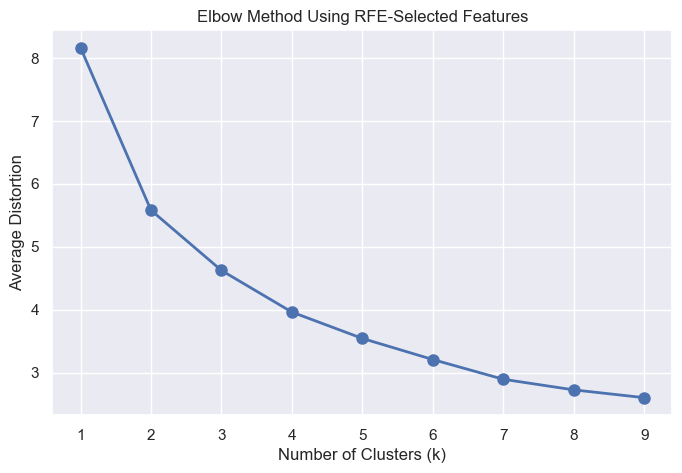

In [512]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
import numpy as np

# Step 1: Clean conversion to array for distance computation
df_rfe_scaled_array = df_rfe_scaled.to_numpy()

# Step 2: Proceed with elbow method
clusters = range(1, 10)
meanDistortions = []

for k in range(1, 10):
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(df_rfe_scaled_array)
    distortion = model.inertia_ / df_rfe_scaled_array.shape[0]  # average distortion per sample
    meanDistortions.append(distortion)

# Step 3: Plot elbow
plt.figure(figsize=(8, 5))
plt.plot(clusters, meanDistortions, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Average Distortion')
plt.title('Elbow Method Using RFE-Selected Features')
plt.grid(True)
plt.show()

In [514]:
model = KMeans(n_clusters=3, random_state=42)
df_scaled['cluster'] = model.fit_predict(df_rfe_scaled_array)

In [516]:
df_scaled.head()

,price,room_bed,room_bath,living_measure,lot_measure,ceil,condition,quality,ceil_measure,living_measure15,lot_measure15,total_area,days_until_2025_06_01,dist_average,house_age_2025,furnished_1,coast_1,cluster
0,600000,0.754198,-0.474754,1.212863,0.154683,1.0,-0.631016,0.413276,0.052500,0.081668,0.088436,0.324447,-1.591772,-0.808799,0.170647,False,False,1
1,190000,-1.594843,-1.497060,-1.665951,-1.113875,1.0,0.913103,-1.596910,-1.446514,-0.481181,-0.961924,-1.298631,-1.229067,-0.766297,0.784052,False,False,0
2,735000,0.754198,0.888321,1.200767,-1.251157,2.0,-0.631016,0.413276,1.697435,1.019749,-1.345904,-0.985147,0.619846,-0.439563,0.170647,False,True,1
3,257000,-0.420322,0.547553,-0.371694,-0.989801,2.0,-0.631016,0.413276,-0.027094,0.097302,-1.032408,-0.984030,0.168676,1.535434,-1.294709,False,False,1
4,450000,-1.594843,-1.497060,-1.121638,-0.815897,1.0,-0.631016,-0.591817,-0.849561,-1.325455,-0.731582,-0.937678,-0.990212,-0.844041,1.601925,False,False,0


In [518]:
# Group by cluster and calculate mean for each feature
cluster_summary = df_scaled.groupby('cluster').mean()

# View the result
print(cluster_summary)

                 price  room_bed  room_bath  living_measure  lot_measure  \
cluster                                                                    
0        397799.690139 -0.421674  -0.889628       -0.715246    -0.144063   
1        485759.092794  0.114849   0.492073        0.054934    -0.559116   
2        739185.378273  0.566173   0.795251        1.183921     1.149841   

             ceil  condition   quality  ceil_measure  living_measure15  \
cluster                                                                  
0        1.154470   0.259282 -0.787493     -0.698536         -0.660847   
1        1.761807  -0.243454  0.204230      0.084055         -0.015739   
2        1.655790  -0.071873  1.073742      1.107662          1.200162   

         lot_measure15  total_area  days_until_2025_06_01  dist_average  \
cluster                                                                   
0            -0.144024   -0.237073              -0.019388     -0.097822   
1            -0.517799 

In [520]:
# Copy cluster labels to original dataframe
df1_with_cluster = df1.copy()
df1_with_cluster['cluster'] = df_scaled['cluster']

In [522]:
# Group by cluster and compute mean from original data
cluster_summary_original = df1_with_cluster.groupby('cluster').mean()

# View the summary
print(cluster_summary_original)

                 price  room_bed  room_bath  living_measure   lot_measure  \
cluster                                                                     
0        397799.690139  2.998849   1.445633     1455.975607   7947.164811   
1        485759.092794  3.455651   2.459299     2092.706387   5873.137933   
2        739185.378273  3.839914   2.681721     3026.072627  14412.821619   

             ceil  condition   quality  ceil_measure  living_measure15  \
cluster                                                                  
0        1.154470   3.576573  6.805316   1233.847658       1545.085177   
1        1.761807   3.250992  7.792013   1823.787366       1957.698629   
2        1.655790   3.362111  8.657119   2595.411620       2735.392270   

         lot_measure15    total_area  days_until_2025_06_01  dist_average  \
cluster                                                                     
0          7650.807934   9473.576901            3865.741342     17.804582   
1          6

In [524]:
X = df1.drop(columns='price')  # features
y = df1['price'] 

In [526]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [528]:
import pandas as pd
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

In [530]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42
)

In [252]:
model = LinearRegression()
model.fit(X_train, y_train)
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

y_train_pred = model.predict(X_train)
print("Linear Training Performance")
print("Training R² Score:", r2_score(y_train, y_train_pred))
print("Training RMSE:", mean_squared_error(y_train, y_train_pred, squared=False))
print("Training MAE:", mean_absolute_error(y_train, y_train_pred))
print("Training MAPE (%):", mean_absolute_percentage_error(y_train, y_train_pred) * 100)

Linear Training Performance
Training R² Score: 0.7675466093723867
Training RMSE: 118581.2113916423
Training MAE: 91052.27554381466
Training MAPE (%): 21.303205285159628


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [253]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error,mean_absolute_percentage_error

y_pred = model.predict(X_test)
print("Linear Test Performance")
print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred, squared=False))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MAPE:", mean_absolute_percentage_error(y_test, y_pred)*100)

Linear Test Performance
R² Score: 0.7603783952786551
RMSE: 119906.0071890196
MAE: 91495.11810507266
MAPE: 21.12942428562837


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [254]:
coeff_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
}).sort_values(by="Coefficient", ascending=False)

print(coeff_df)

                  Feature   Coefficient
2          living_measure  74262.077469
6                 quality  69295.073797
13         house_age_2025  50291.740338
10             total_area  48169.924207
8        living_measure15  29128.793805
1               room_bath  23818.091774
14            furnished_1  20947.689304
15                coast_1  20191.449522
5               condition  16317.247242
4                    ceil   9964.478379
7            ceil_measure   5454.583166
9           lot_measure15  -1278.593351
11  days_until_2025_06_01  -9158.623122
0                room_bed -18895.165554
3             lot_measure -41676.095084
12           dist_average -87813.557335


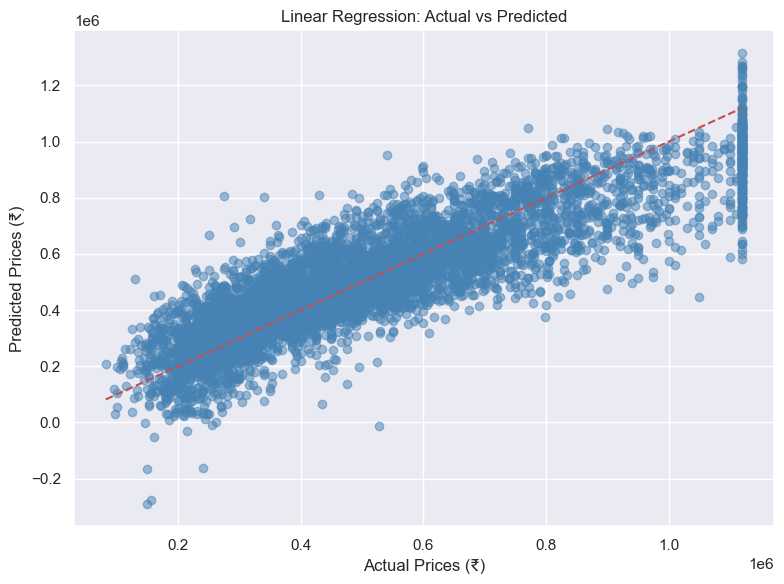

In [255]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5, color='steelblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Prices (₹)")
plt.ylabel("Predicted Prices (₹)")
plt.title("Linear Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()

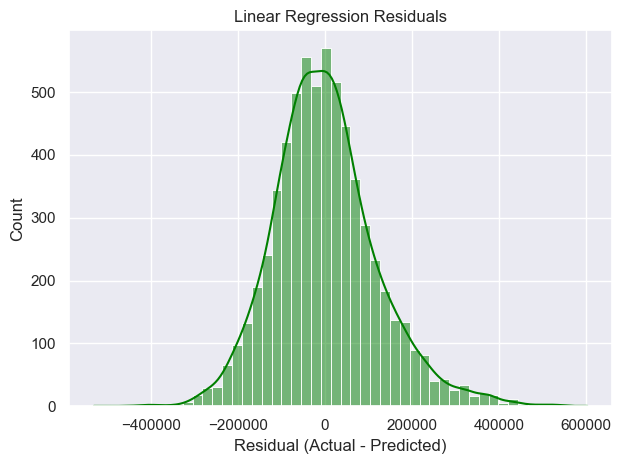

In [256]:
import seaborn as sns

residuals = y_test - y_pred
sns.histplot(residuals, bins=50, kde=True, color='green')
plt.title("Linear Regression Residuals")
plt.xlabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

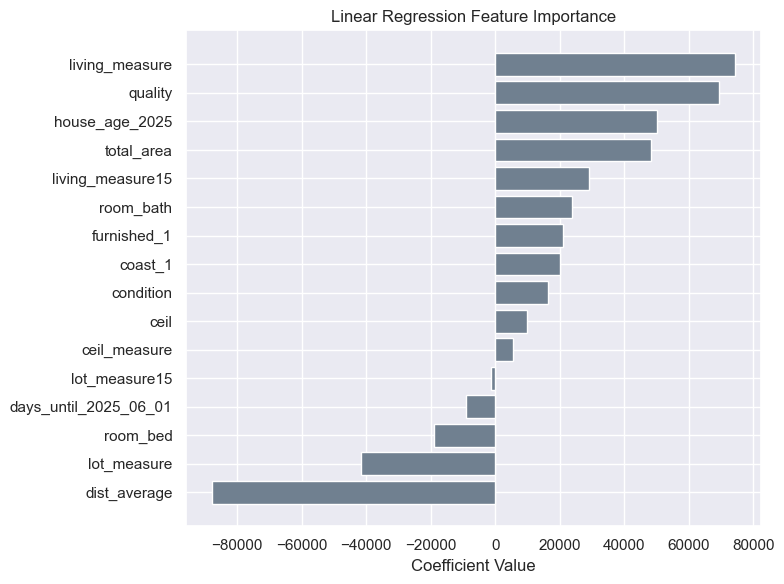

In [257]:
import pandas as pd
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

coefs = lr.coef_  # Assuming you trained model as `lr = LinearRegression().fit(...)`
features = X.columns

coef_df = pd.DataFrame({
    "Feature": features,
    "Coefficient": coefs
}).sort_values(by="Coefficient", ascending=True)

plt.figure(figsize=(8,6))
plt.barh(coef_df["Feature"], coef_df["Coefficient"], color='slategray')
plt.xlabel("Coefficient Value")
plt.title("Linear Regression Feature Importance")
plt.tight_layout()
plt.show()

In [258]:
###lasso
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Use your scaled features and original target
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Fit Lasso with chosen alpha
lasso = Lasso(alpha=500)  # tweak alpha to control shrinkage strength
lasso.fit(X_train, y_train)

Lasso(alpha=500)

In [259]:
y_train_pred = lasso.predict(X_train)

y_train_pred = model.predict(X_train)
print("Linear Training Performance")
print("Training R² Score:", r2_score(y_train, y_train_pred))
print("Training RMSE:", mean_squared_error(y_train, y_train_pred, squared=False))
print("Training MAE:", mean_absolute_error(y_train, y_train_pred))
print("Training MAPE (%):", mean_absolute_percentage_error(y_train, y_train_pred) * 100)

Linear Training Performance
Training R² Score: 0.7676522552123476
Training RMSE: 118487.130471492
Training MAE: 90979.02597896683
Training MAPE (%): 21.245102053725944


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [260]:
y_pred = lasso.predict(X_test)

print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred, squared=False))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("Training MAPE (%):", mean_absolute_percentage_error(y_train, y_train_pred) * 100)

R² Score: 0.7560010812397471
RMSE: 121023.23827630619
MAE: 92114.04329901436
Training MAPE (%): 21.245102053725944


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [261]:
import pandas as pd

lasso_coeffs = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lasso.coef_
}).sort_values(by="Coefficient", ascending=False)

print(lasso_coeffs)

                  Feature   Coefficient
2          living_measure  80027.265152
6                 quality  68920.595169
13         house_age_2025  49649.573272
8        living_measure15  29378.862422
1               room_bath  22216.768351
14            furnished_1  21134.602531
15                coast_1  20152.984005
5               condition  15484.936561
4                    ceil  10263.842703
7            ceil_measure   4294.020363
10             total_area   2657.648922
3             lot_measure     -0.000000
9           lot_measure15     -0.000000
11  days_until_2025_06_01  -9192.148364
0                room_bed -16816.721179
12           dist_average -88093.028314


In [262]:
from sklearn.linear_model import LassoCV

lasso_cv = LassoCV(alphas=[10, 100, 500, 1000, 2000], cv=5)
lasso_cv.fit(X_train, y_train)

print("Best alpha:", lasso_cv.alpha_)

Best alpha: 10


In [263]:
from sklearn.linear_model import Lasso

# Use the best alpha found via cross-validation
lasso_opt = Lasso(alpha=10)
lasso_opt.fit(X_train, y_train) 

Lasso(alpha=10)

In [264]:
y_train_lasso_pred = lasso_opt.predict(X_train)

print("Lasso Training Performance")
print("R² Score:", r2_score(y_train, y_train_lasso_pred))
print("RMSE:", mean_squared_error(y_train, y_train_lasso_pred, squared=False))
print("MAE:", mean_absolute_error(y_train, y_train_lasso_pred))
print("MAPE (%):", mean_absolute_percentage_error(y_train, y_train_lasso_pred) * 100)

Lasso Training Performance
R² Score: 0.767697384090656
RMSE: 118475.62304117807
MAE: 91031.52205982387
MAPE (%): 21.297011173190004


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [265]:
# Predict and evaluate
y_pred = lasso_opt.predict(X_test)

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
print("Test Set OPerformance:")
print("R²:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred, squared=False))
print("MAE:", mean_absolute_error(y_test, y_pred))
print(" MAPE (%):", mean_absolute_percentage_error(y_train, y_train_pred) * 100)

Test Set OPerformance:
R²: 0.756381798519661
RMSE: 120928.78370745068
MAE: 92054.94732470106
 MAPE (%): 21.245102053725944


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [266]:
import pandas as pd

coeffs = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lasso_opt.coef_
}).query("Coefficient != 0").sort_values(by="Coefficient", ascending=False)

print(coeffs)

                  Feature   Coefficient
2          living_measure  74948.013779
6                 quality  68988.052670
13         house_age_2025  50762.863275
10             total_area  40132.086894
8        living_measure15  29526.415235
1               room_bath  23288.450102
14            furnished_1  21372.427281
15                coast_1  20504.534210
5               condition  16087.823285
4                    ceil  10285.467291
7            ceil_measure   5263.260393
9           lot_measure15  -1695.038992
11  days_until_2025_06_01  -9791.387917
0                room_bed -18289.241011
3             lot_measure -33952.803442
12           dist_average -88345.735624


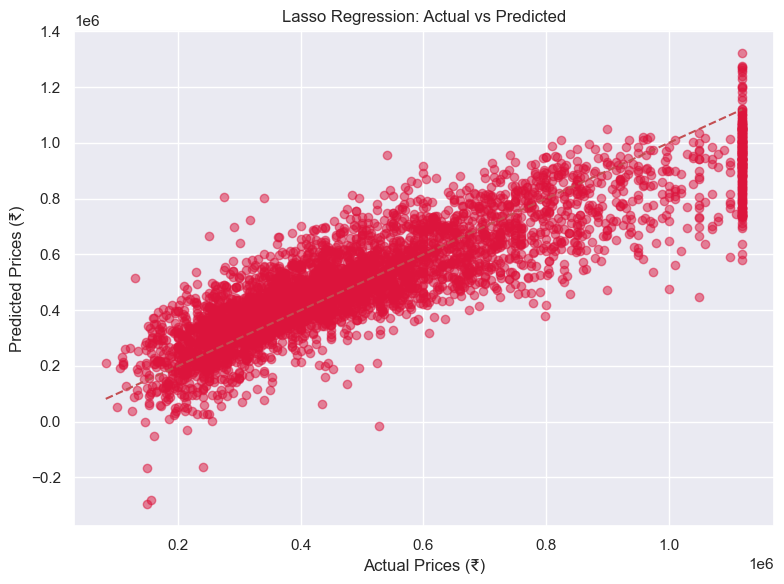

In [267]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5, color='crimson')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Prices (₹)")
plt.ylabel("Predicted Prices (₹)")
plt.title("Lasso Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()

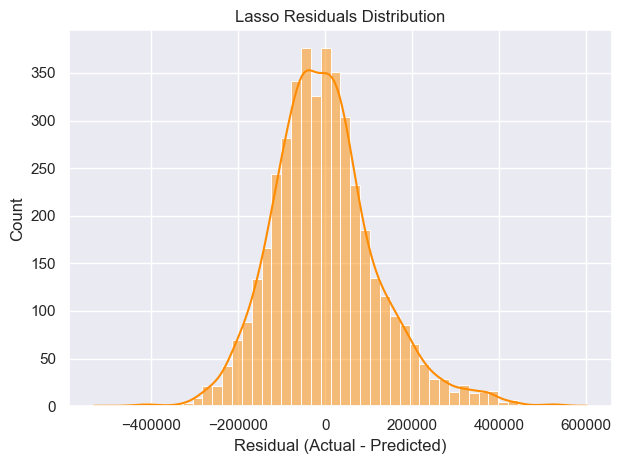

In [268]:
import seaborn as sns

residuals = y_test - y_pred
sns.histplot(residuals, bins=50, kde=True, color='darkorange')
plt.title("Lasso Residuals Distribution")
plt.xlabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

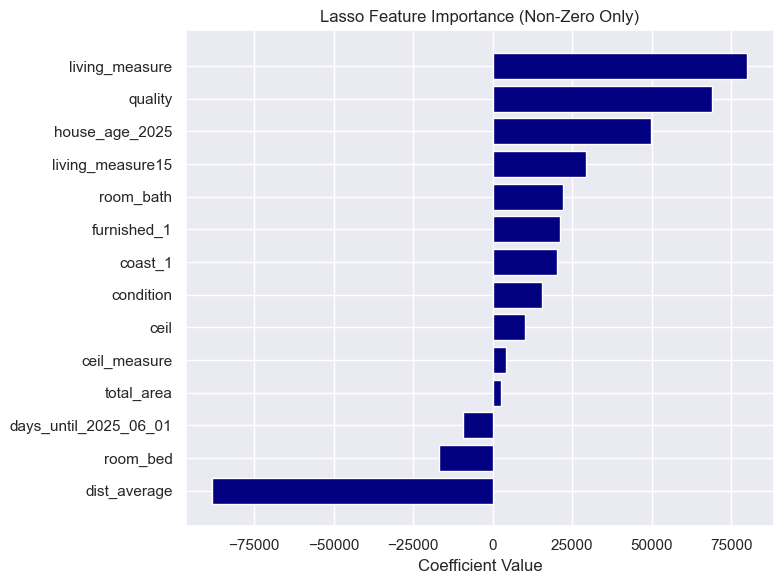

In [269]:
import pandas as pd
import numpy as np

coefs = lasso.coef_  # assuming you trained: lasso = Lasso().fit(...)
features = X.columns

importance_df = pd.DataFrame({
    "Feature": features,
    "Coefficient": coefs
})

# Filter only features with non-zero impact
non_zero_df = importance_df[importance_df["Coefficient"] != 0].sort_values(by="Coefficient", ascending=True)

# Plot
plt.figure(figsize=(8,6))
plt.barh(non_zero_df["Feature"], non_zero_df["Coefficient"], color='navy')
plt.xlabel("Coefficient Value")
plt.title("Lasso Feature Importance (Non-Zero Only)")
plt.tight_layout()
plt.show()

In [271]:
####ridge

In [272]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Use your scaled features and original target
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42
)

In [273]:
ridge = Ridge(alpha=10)  # start with 10,
ridge.fit(X_train, y_train)

Ridge(alpha=10)

In [274]:
y_train_ridge_pred = ridge.predict(X_train)

print("Ridge Training Performance")
print("R² Score:", r2_score(y_train, y_train_ridge_pred))
print("RMSE:", mean_squared_error(y_train, y_train_ridge_pred, squared=False))
print("MAE:", mean_absolute_error(y_train, y_train_ridge_pred))
print("MAPE (%):", mean_absolute_percentage_error(y_train, y_train_ridge_pred) * 100)

Ridge Training Performance
R² Score: 0.7675436444807454
RMSE: 118581.96762780742
MAE: 91053.410688501
MAPE (%): 21.301160747616287


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [275]:
y_pred = ridge.predict(X_test)

print("Ridge Test Performance")
print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred, squared=False))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MAPE (%):", mean_absolute_percentage_error(y_test, y_pred) * 100)

Ridge Test Performance
R² Score: 0.7604173108900543
RMSE: 119896.2701599764
MAE: 91481.27547674377
MAPE (%): 21.12368595642275


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [276]:
import pandas as pd

coeffs = pd.DataFrame({
    "Feature": X.columns,
    "Ridge Coefficient": ridge.coef_
}).sort_values(by="Ridge Coefficient", ascending=False)

print(coeffs)

                  Feature  Ridge Coefficient
2          living_measure       74463.160526
6                 quality       69188.800385
13         house_age_2025       50245.024328
10             total_area       44801.755184
8        living_measure15       29181.393134
1               room_bath       23857.049436
14            furnished_1       20994.268024
15                coast_1       20189.793168
5               condition       16320.088833
4                    ceil        9963.575324
7            ceil_measure        5580.501918
9           lot_measure15       -1280.633697
11  days_until_2025_06_01       -9149.296580
0                room_bed      -18816.206751
3             lot_measure      -38477.580306
12           dist_average      -87785.725013


In [277]:
from sklearn.linear_model import RidgeCV

ridge_cv = RidgeCV(alphas=[1, 5, 10, 50, 100], cv=5)
ridge_cv.fit(X_train, y_train)

print("Optimal alpha:", ridge_cv.alpha_)

Optimal alpha: 10


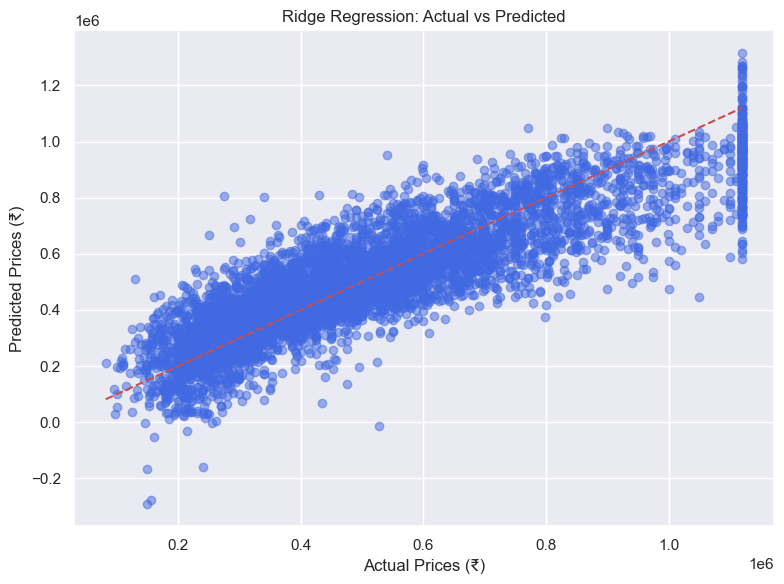

In [278]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5, color='royalblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Prices (₹)")
plt.ylabel("Predicted Prices (₹)")
plt.title("Ridge Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()

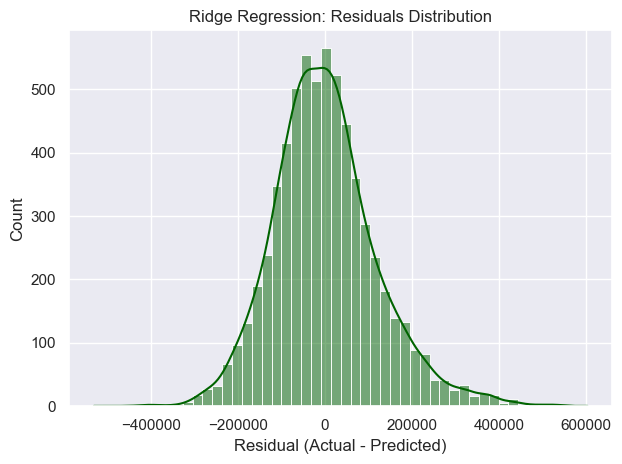

In [279]:
import seaborn as sns

residuals = y_test - y_pred
sns.histplot(residuals, bins=50, kde=True, color='darkgreen')
plt.title("Ridge Regression: Residuals Distribution")
plt.xlabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

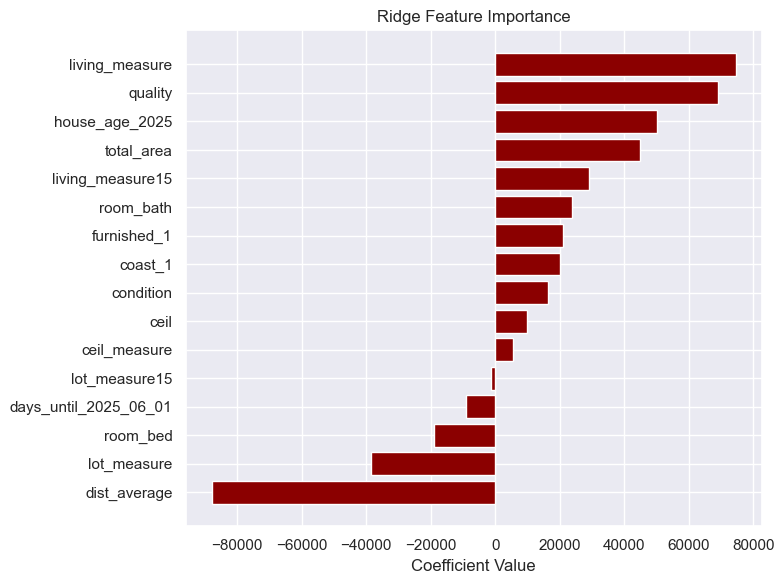

In [280]:
import pandas as pd

coefs = ridge.coef_  # assuming you trained Ridge via ridge = Ridge().fit(...)
features = X.columns

importance_df = pd.DataFrame({
    "Feature": features,
    "Coefficient": coefs
}).sort_values(by="Coefficient", ascending=True)

plt.figure(figsize=(8,6))
plt.barh(importance_df["Feature"], importance_df["Coefficient"], color='darkred')
plt.xlabel("Coefficient Value")
plt.title("Ridge Feature Importance")
plt.tight_layout()
plt.show()

In [281]:
#####POLYNOMIAL

In [282]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

In [283]:
model = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())

In [284]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Fit the model
model.fit(X_train, y_train)

# Predictions
y_test_pred = model.predict(X_test)
y_train_pred = model.predict(X_train)

# Test set metrics
print("Test R² Score:", r2_score(y_test, y_test_pred))
print("Test RMSE:", mean_squared_error(y_test, y_test_pred, squared=False))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))
print("Test MAPE (%):", mean_absolute_percentage_error(y_test, y_test_pred) * 100)

# Training set metrics
print("Train R² Score:", r2_score(y_train, y_train_pred))
print("Train RMSE:", mean_squared_error(y_train, y_train_pred, squared=False))
print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Train MAPE (%):", mean_absolute_percentage_error(y_train, y_train_pred) * 100)

Test R² Score: 0.816993640797176
Test RMSE: 104787.87801093986
Test MAE: 76981.17455788408
Test MAPE (%): 17.119144862993814
Train R² Score: 0.8262526391521168
Train RMSE: 102519.63428877459
Train MAE: 76370.4679329588
Train MAPE (%): 16.969485886892606


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [285]:
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)
print(poly.get_feature_names_out(X.columns))

['1' 'room_bed' 'room_bath' 'living_measure' 'lot_measure' 'ceil'
 'condition' 'quality' 'ceil_measure' 'living_measure15' 'lot_measure15'
 'total_area' 'days_until_2025_06_01' 'dist_average' 'house_age_2025'
 'furnished_1' 'coast_1' 'room_bed^2' 'room_bed room_bath'
 'room_bed living_measure' 'room_bed lot_measure' 'room_bed ceil'
 'room_bed condition' 'room_bed quality' 'room_bed ceil_measure'
 'room_bed living_measure15' 'room_bed lot_measure15'
 'room_bed total_area' 'room_bed days_until_2025_06_01'
 'room_bed dist_average' 'room_bed house_age_2025' 'room_bed furnished_1'
 'room_bed coast_1' 'room_bath^2' 'room_bath living_measure'
 'room_bath lot_measure' 'room_bath ceil' 'room_bath condition'
 'room_bath quality' 'room_bath ceil_measure' 'room_bath living_measure15'
 'room_bath lot_measure15' 'room_bath total_area'
 'room_bath days_until_2025_06_01' 'room_bath dist_average'
 'room_bath house_age_2025' 'room_bath furnished_1' 'room_bath coast_1'
 'living_measure^2' 'living_measure

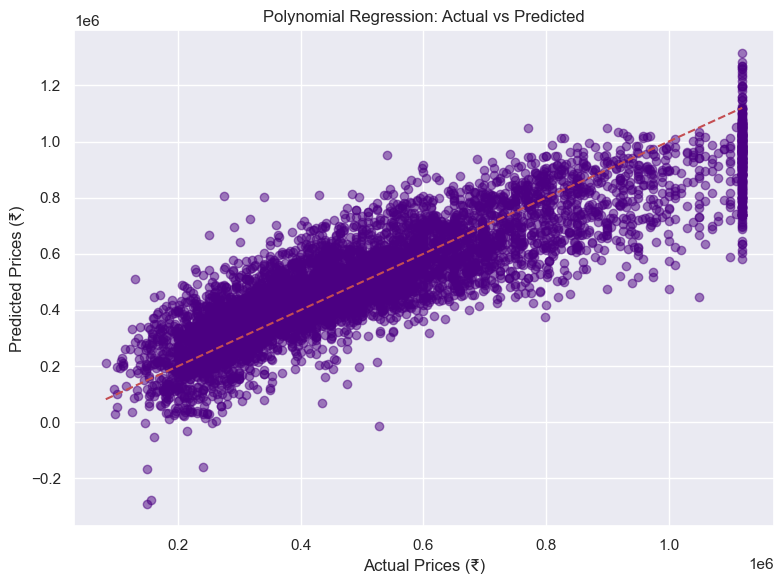

In [286]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5, color='indigo')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Prices (₹)")
plt.ylabel("Predicted Prices (₹)")
plt.title("Polynomial Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()

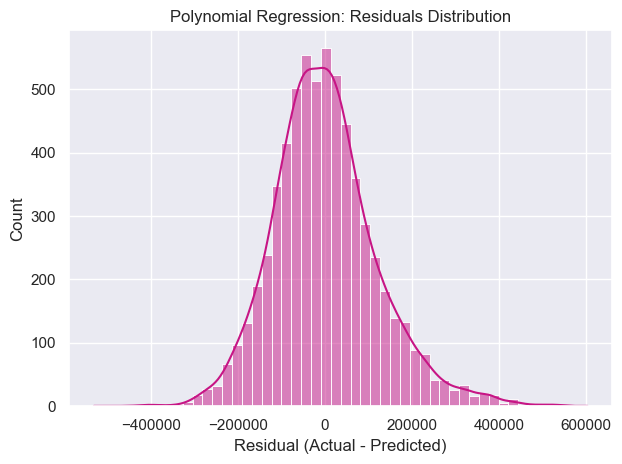

In [287]:
import seaborn as sns

residuals = y_test - y_pred
sns.histplot(residuals, bins=50, kde=True, color='mediumvioletred')
plt.title("Polynomial Regression: Residuals Distribution")
plt.xlabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

In [288]:
from sklearn.inspection import permutation_importance

# Fit your model on transformed data
model.fit(X_poly_train, y_train)

# Evaluate importance on test set
result = permutation_importance(model, X_poly_test, y_test, n_repeats=10, random_state=42)

# Use feature names from PolynomialFeatures
feature_names = poly.get_feature_names_out(X.columns)

# Create importance DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": result.importances_mean
}).sort_values(by="Importance", ascending=False)

# Plot
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color='mediumseagreen')
plt.xlabel("Permutation Importance")
plt.title("Feature Importance on Test Set (Polynomial Regression)")
plt.tight_layout()
plt.show()

NameError: name 'X_poly_train' is not defined

In [307]:
###RandomForest

In [308]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42
)

In [309]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)  # Train the model

RandomForestRegressor(random_state=42)

In [310]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Predictions
y_test_pred = rf.predict(X_test)
y_train_pred = rf.predict(X_train)

# Test set metrics
print("Test R² Score:", r2_score(y_test, y_test_pred))
print("Test RMSE:", mean_squared_error(y_test, y_test_pred, squared=False))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))
print("Test MAPE (%):", mean_absolute_percentage_error(y_test, y_test_pred) * 100)

Test R² Score: 0.839279213678313
Test RMSE: 98200.5634247564
Test MAE: 69167.08686285967
Test MAPE (%): 15.299203117485332


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [311]:
# Training set metrics
print("Train R² Score:", r2_score(y_train, y_train_pred))
print("Train RMSE:", mean_squared_error(y_train, y_train_pred, squared=False))
print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Train MAPE (%):", mean_absolute_percentage_error(y_train, y_train_pred) * 100)

Train R² Score: 0.9779804037834811
Train RMSE: 36496.617453589926
Train MAE: 25630.116307471046
Train MAPE (%): 5.717947903825011


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [312]:
print("y_test shape:", y_test.shape)
print("y_pred shape:", y_pred.shape)

y_test shape: (6418,)
y_pred shape: (6418,)


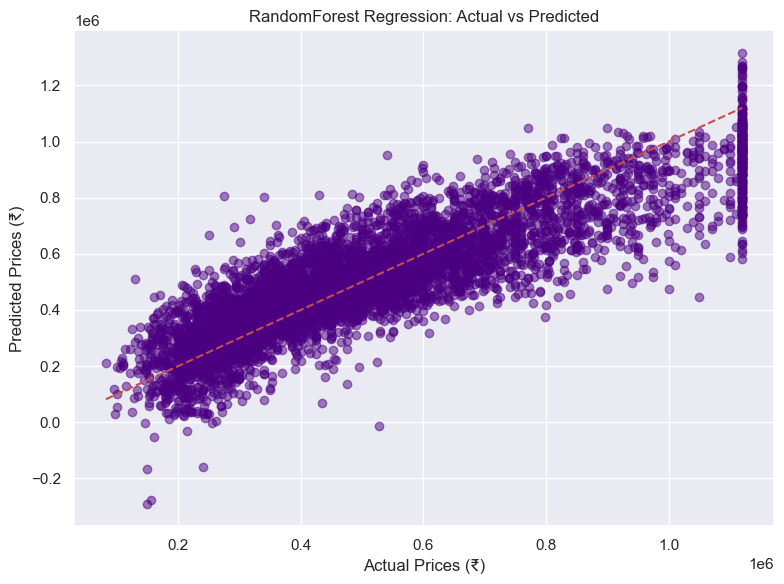

In [313]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5, color='indigo')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Prices (₹)")
plt.ylabel("Predicted Prices (₹)")
plt.title("RandomForest Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()

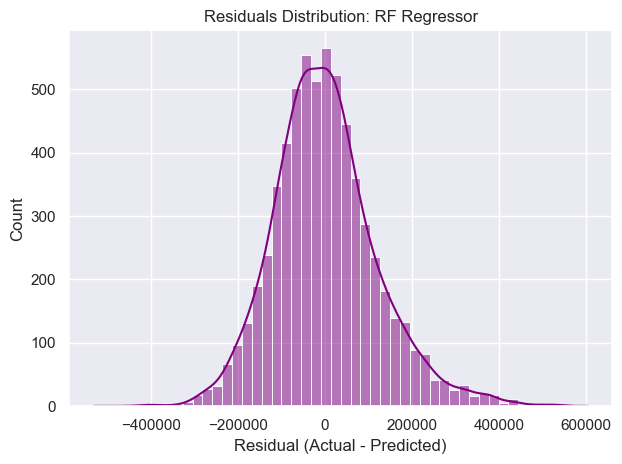

In [314]:
import seaborn as sns

residuals = y_test - y_pred
sns.histplot(residuals, bins=50, kde=True, color='purple')
plt.title("Residuals Distribution: RF Regressor")
plt.xlabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

coefs = ridge.coef_  # assuming you trained Ridge via ridge = Ridge().fit(...)
features = X.columns

importance_df = pd.DataFrame({
    "Feature": features,
    "Coefficient": coefs
}).sort_values(by="Coefficient", ascending=True)

plt.figure(figsize=(8,6))
plt.barh(importance_df["Feature"], importance_df["Coefficient"], color='darkred')
plt.xlabel("Coefficient Value")
plt.title("Ridge Feature Importance")
plt.tight_layout()
plt.show()

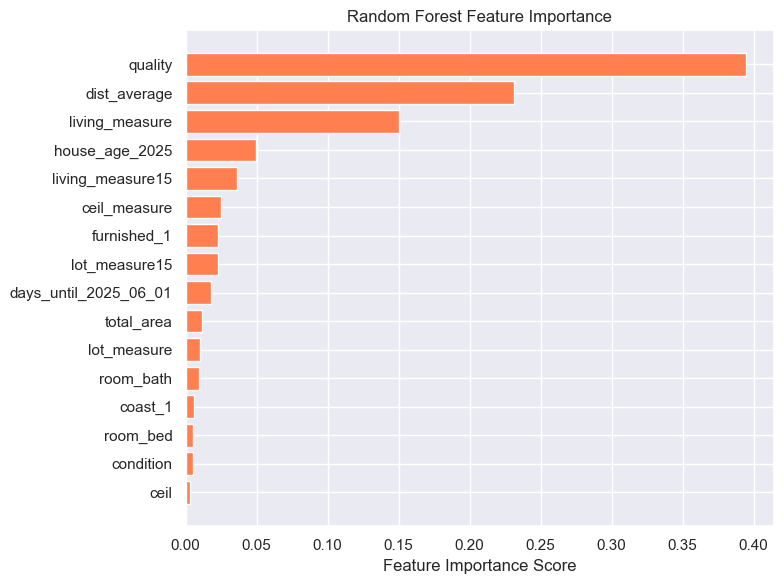

In [315]:
import pandas as pd

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(8,6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color='coral')
plt.xlabel("Feature Importance Score")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [532]:
###xg 
X = df2.drop(columns='price')  # features
y = df2['price'] 

In [534]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [536]:
import pandas as pd
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

In [538]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [539]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42
)

In [540]:
xgb_model = xgb.XGBRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=None, num_parallel_tree=None, ...)

In [544]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Predictions
y_test_pred = xgb_model.predict(X_test)
y_train_pred = xgb_model.predict(X_train)

# Test set metrics
print("Test R² Score:", r2_score(y_test, y_test_pred))
print("Test RMSE:", mean_squared_error(y_test, y_test_pred, squared=False))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))
print("Test MAPE (%):", mean_absolute_percentage_error(y_test, y_test_pred) * 100)

# Training set metrics
print("Train R² Score:", r2_score(y_train, y_train_pred))
print("Train RMSE:", mean_squared_error(y_train, y_train_pred, squared=False))
print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Train MAPE (%):", mean_absolute_percentage_error(y_train, y_train_pred) * 100)

Test R² Score: 0.8398384380941382
Test RMSE: 122330.1272744072
Test MAE: 79703.84961363548
Test MAPE (%): 16.147579815974396
Train R² Score: 0.9174627771573282
Train RMSE: 88565.27644981904
Train MAE: 64071.71709191766
Train MAPE (%): 14.036746616722844


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [546]:
###xg 
X = df1.drop(columns='price')  # features
y = df1['price'] 

In [548]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [550]:
import pandas as pd
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

In [552]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42
)

In [554]:
xgb_model = xgb.XGBRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=None, num_parallel_tree=None, ...)

In [556]:
y_pred = xgb_model.predict(X_train)
print("train")
print("R² Score:", r2_score(y_train, y_pred))
print("RMSE:", mean_squared_error(y_train, y_pred, squared=False))
print("MAE:", mean_absolute_error(y_train, y_pred))
print("Train MAPE (%):", mean_absolute_percentage_error(y_train, y_pred) * 100)

train
R² Score: 0.9018441572799099
RMSE: 77055.92142269762
MAE: 57269.461574019966
Train MAPE (%): 13.061389473737792


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [558]:
y_pred = xgb_model.predict(X_test)
print("Test performance")
print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred, squared=False))
print("MAE:", mean_absolute_error(y_test, y_pred))
print(" MAPE (%):", mean_absolute_percentage_error(y_test, y_pred) * 100)

Test performance
R² Score: 0.847086358040449
RMSE: 95785.78688250188
MAE: 69028.70569345981
 MAPE (%): 15.298493320333275


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


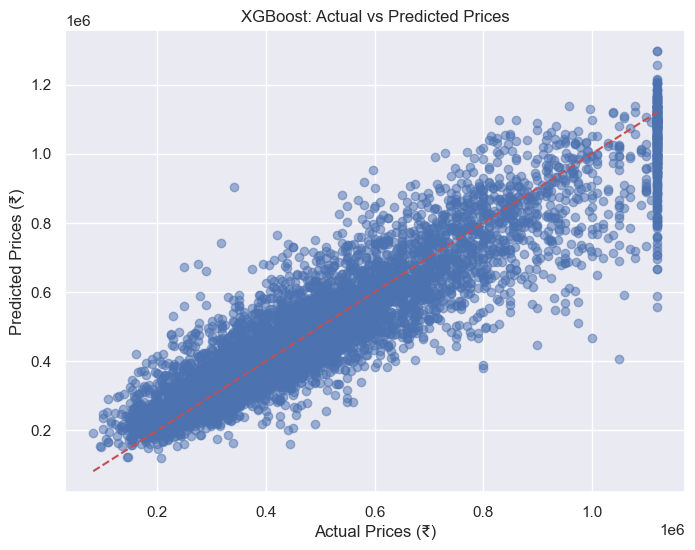

In [330]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual Prices (₹)")
plt.ylabel("Predicted Prices (₹)")
plt.title("XGBoost: Actual vs Predicted Prices")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # reference line
plt.show()

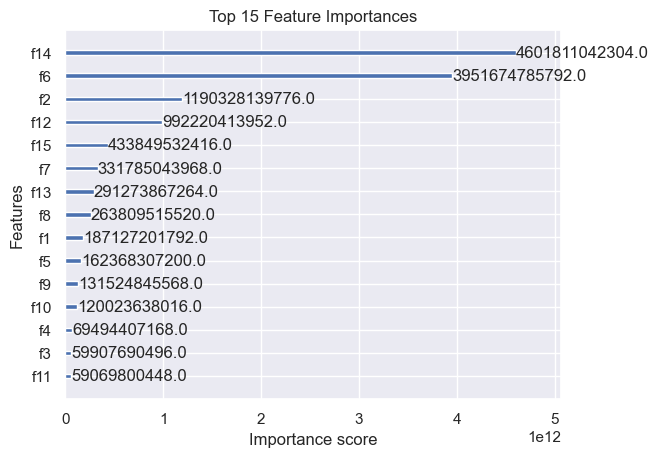

In [331]:
import xgboost as xgb

xgb.plot_importance(xgb_model, importance_type='gain', max_num_features=15)
plt.title("Top 15 Feature Importances")
plt.show()

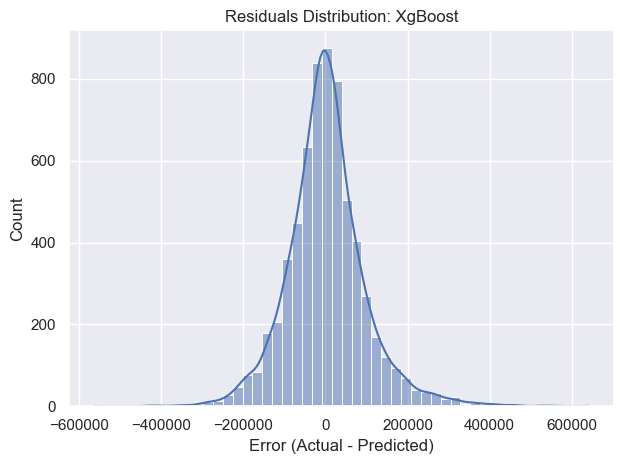

In [332]:
import seaborn as sns

residuals = y_test - y_pred
sns.histplot(residuals, bins=50, kde=True)
plt.title("Residuals Distribution: XgBoost")
plt.xlabel("Error (Actual - Predicted)")
plt.tight_layout()
plt.show()

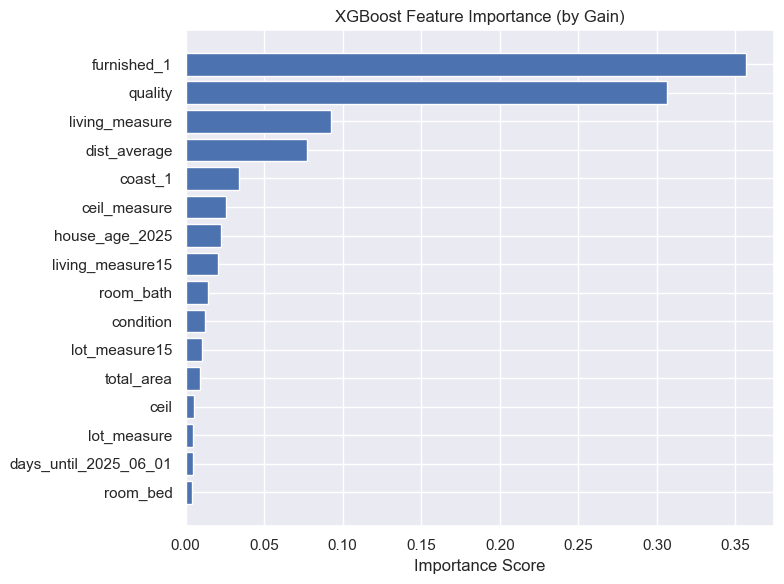

In [333]:
import pandas as pd
import matplotlib.pyplot as plt

# Get raw importances and match to real feature names
importance_scores = xgb_model.feature_importances_
features = X.columns  # make sure this matches your X data

# Combine into a DataFrame
feat_imp_df = pd.DataFrame({
    'Feature': features,
    'Importance': importance_scores
}).sort_values(by='Importance', ascending=True)

# Plot using matplotlib
plt.figure(figsize=(8, 6))
plt.barh(feat_imp_df['Feature'], feat_imp_df['Importance'])
plt.xlabel('Importance Score')
plt.title('XGBoost Feature Importance (by Gain)')
plt.tight_layout()
plt.show()

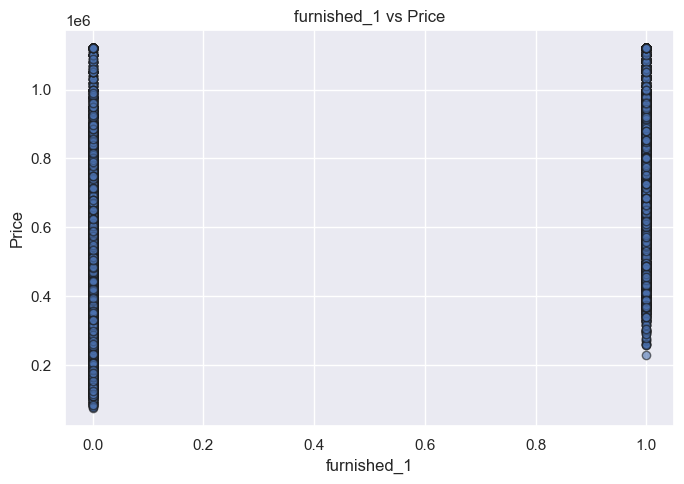

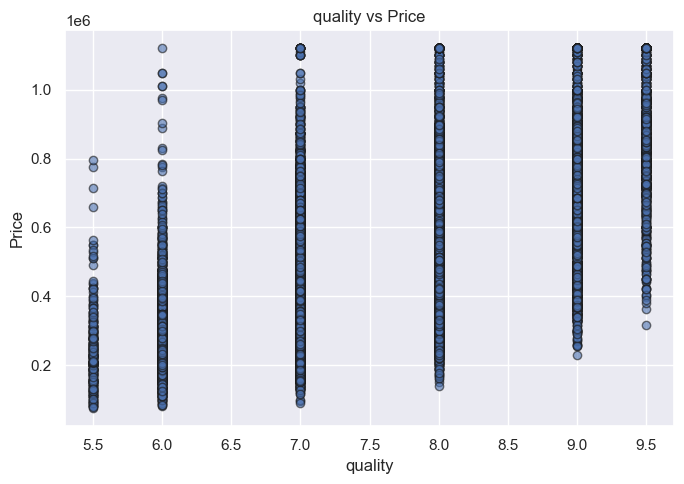

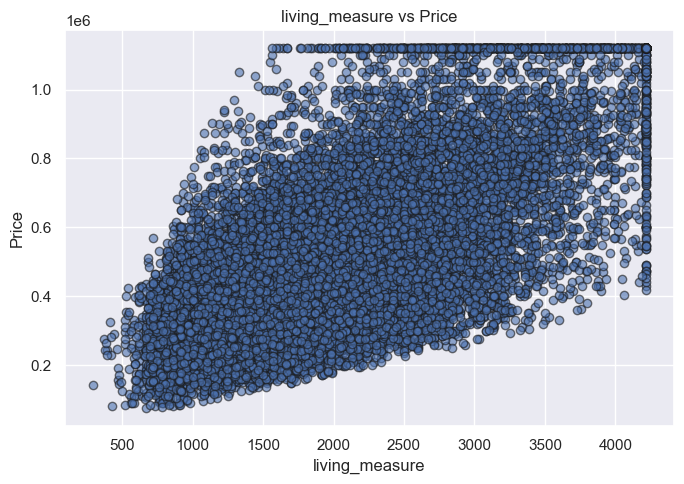

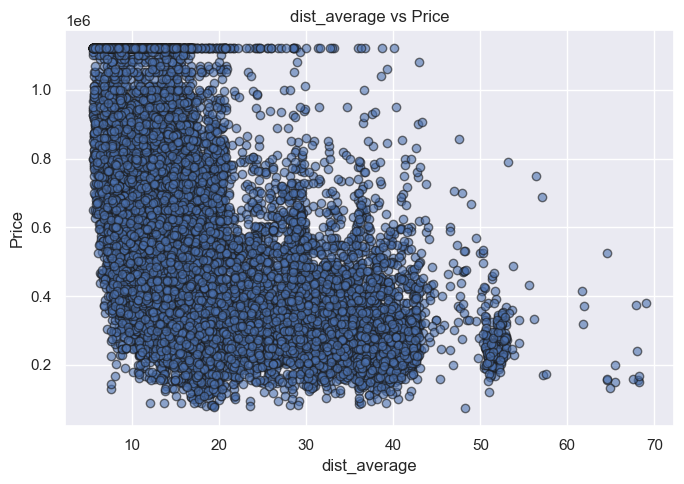

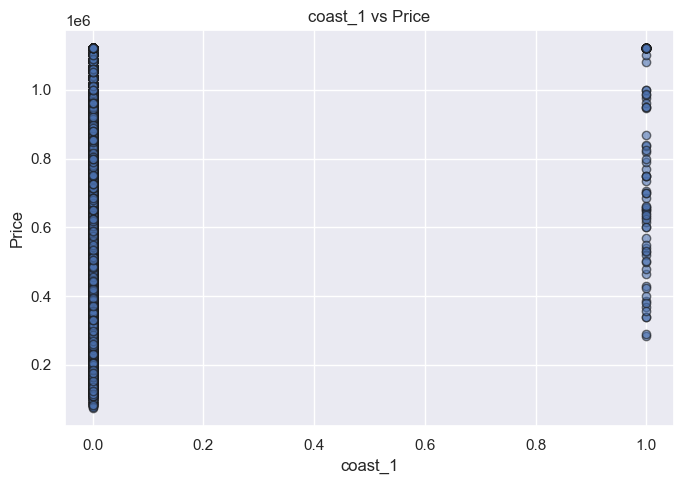

In [334]:
top_feats = feat_imp_df.sort_values(by='Importance', ascending=False).head(5)['Feature']

for feature in top_feats:
    plt.figure(figsize=(7, 5))
    plt.scatter(X[feature], y, alpha=0.6, edgecolor='k')
    plt.xlabel(feature)
    plt.ylabel('Price')
    plt.title(f'{feature} vs Price')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [335]:
for feature in top_feats:
    corr = X[feature].corr(y)
    print(f"{feature} correlation with price: {corr:.3f}")

furnished_1 correlation with price: 0.607
quality correlation with price: 0.680
living_measure correlation with price: 0.691
dist_average correlation with price: -0.476
coast_1 correlation with price: 0.125


In [336]:
from sklearn.linear_model import LinearRegression

top_feats = feat_imp_df.sort_values(by='Importance', ascending=False).head(5)['Feature']
X_linear = X[top_feats]
linreg = LinearRegression()
linreg.fit(X_linear, y)

coefs = pd.Series(linreg.coef_, index=top_feats)
intercept = linreg.intercept_

In [337]:
equation = f"Price = {intercept:.2f} " + " + ".join([f"{coef:.2f}·{feat}" for feat, coef in coefs.items()])
print(equation)

Price = 21947.44 75778.70·furnished_1 + 53008.72·quality + 127.15·living_measure + -10282.49·dist_average + 314740.89·coast_1


In [338]:
####Adabooster
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
X = df1.drop(columns='price')  # features
y = df1['price'] 

In [339]:
# Step 1: Feature Scaling (optional but useful for tree depth control)
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 2: Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42
)

# Step 3: Define base learner and AdaBoost model
base_model = DecisionTreeRegressor(max_depth=4)

from sklearn.ensemble import AdaBoostRegressor  # Make sure this import matches your sklearn version
ada_model = AdaBoostRegressor(
    estimator=base_model,  # Use 'estimator' for older sklearn; 'base_estimator' for newer
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

In [340]:
# Step 4: Fit the model
ada_model.fit(X_train, y_train)

# Step 5a: Predict and evaluate on Test Set
y_test_pred = ada_model.predict(X_test)
print(" Test Set Performance")
print("R² Score:", r2_score(y_test, y_test_pred))
print("RMSE:", mean_squared_error(y_test, y_test_pred, squared=False))
print("MAE:", mean_absolute_error(y_test, y_test_pred))
print(" MAPE (%):", mean_absolute_percentage_error(y_test, y_test_pred) * 100)

# Step 5b: Predict and evaluate on Training Set
y_train_pred = ada_model.predict(X_train)
print("Training Set Performance")
print("R² Score:", r2_score(y_train, y_train_pred))
print("RMSE:", mean_squared_error(y_train, y_train_pred, squared=False))
print("MAE:", mean_absolute_error(y_train, y_train_pred))
print(" MAPE (%):", mean_absolute_percentage_error(y_train, y_train_pred) * 100)

 Test Set Performance
R² Score: 0.7146777880073703
RMSE: 130841.56992306585
MAE: 107414.8611695437
 MAPE (%): 27.48969759947898


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


Training Set Performance
R² Score: 0.7316113866377034
RMSE: 127417.76508961129
MAE: 105460.47190844046
 MAPE (%): 27.23658356363582


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


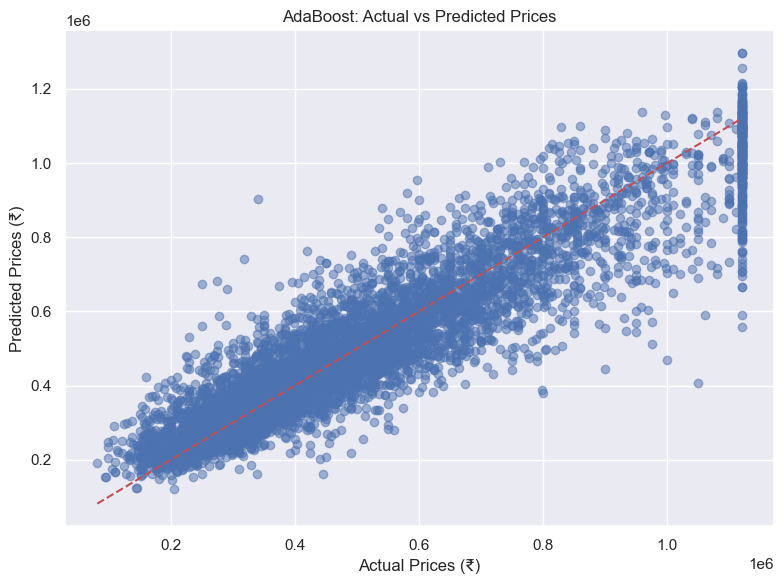

In [341]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual Prices (₹)")
plt.ylabel("Predicted Prices (₹)")
plt.title("AdaBoost: Actual vs Predicted Prices")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.tight_layout()
plt.show()

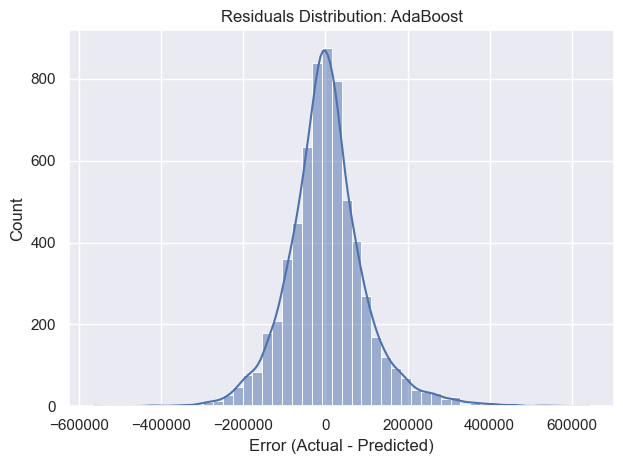

In [342]:
import seaborn as sns

residuals = y_test - y_pred
sns.histplot(residuals, bins=50, kde=True)
plt.title("Residuals Distribution: AdaBoost")
plt.xlabel("Error (Actual - Predicted)")
plt.tight_layout()
plt.show()

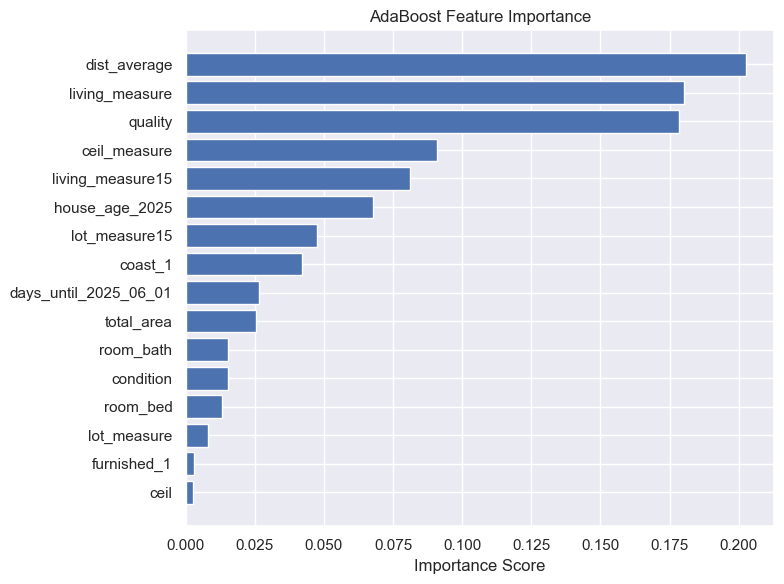

In [343]:
import pandas as pd
import numpy as np

# Access feature importance from the fitted AdaBoost model
feat_importances = ada_model.feature_importances_
features = X.columns

# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": feat_importances
}).sort_values(by="Importance", ascending=True)

# Plot
plt.figure(figsize=(8,6))
plt.barh(importance_df["Feature"], importance_df["Importance"])
plt.xlabel("Importance Score")
plt.title("AdaBoost Feature Importance")
plt.tight_layout()
plt.show()

In [344]:
####SVM
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [345]:
from sklearn.svm import SVR

svr_model = SVR(
    kernel='rbf',     # use 'linear' or 'poly' for other styles
    C=100,            # regularization strength
    epsilon=10000     # tolerance for error margin
)

svr_model.fit(X_train, y_train)

SVR(C=100, epsilon=10000)

In [346]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

y_pred = svr_model.predict(X_train)
print("Training Score")
print("R² Score:", r2_score(y_train, y_pred))
print("RMSE:", mean_squared_error(y_train, y_pred, squared=False))
print("MAE:", mean_absolute_error(y_train, y_pred))
print(" MAPE (%):", mean_absolute_percentage_error(y_train, y_pred) * 100)

Training Score
R² Score: 0.2873616150326296
RMSE: 207626.38647349318
MAE: 152531.4989119432
 MAPE (%): 32.85628550680387


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [347]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

y_pred = svr_model.predict(X_test)
print("Test Score")
print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred, squared=False))
print("MAE:", mean_absolute_error(y_test, y_pred))
print(" MAPE (%):", mean_absolute_percentage_error(y_test, y_pred) * 100)

Test Score
R² Score: 0.2801247597262746
RMSE: 207829.203667744
MAE: 153056.3269792666
 MAPE (%): 32.72524054449291


C:\Users\cylik\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


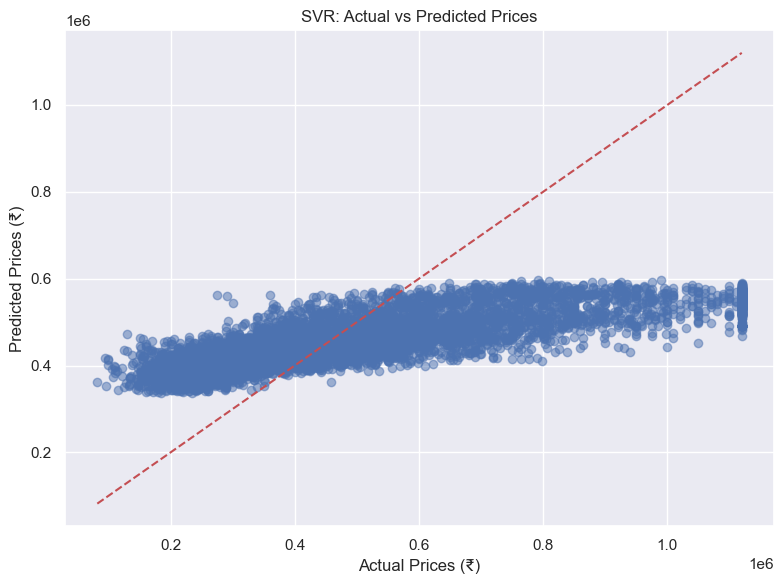

In [348]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual Prices (₹)")
plt.ylabel("Predicted Prices (₹)")
plt.title("SVR: Actual vs Predicted Prices")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # reference line
plt.tight_layout()
plt.show()

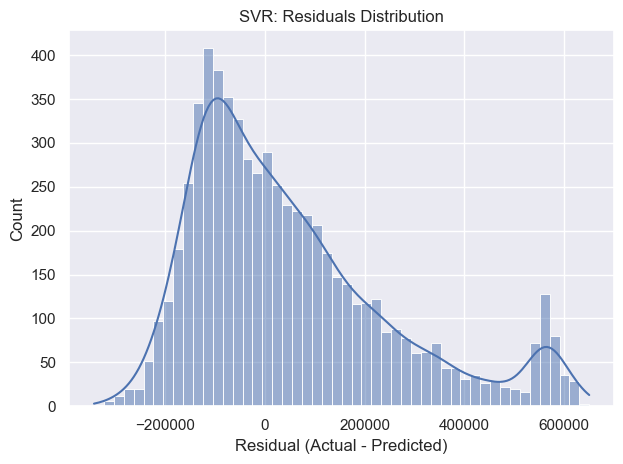

In [349]:
import seaborn as sns

residuals = y_test - y_pred
sns.histplot(residuals, bins=50, kde=True)
plt.title("SVR: Residuals Distribution")
plt.xlabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

In [350]:
n_support = svr_model.support_.shape[0]
print(f"Total support vectors used: {n_support}")

Total support vectors used: 14286


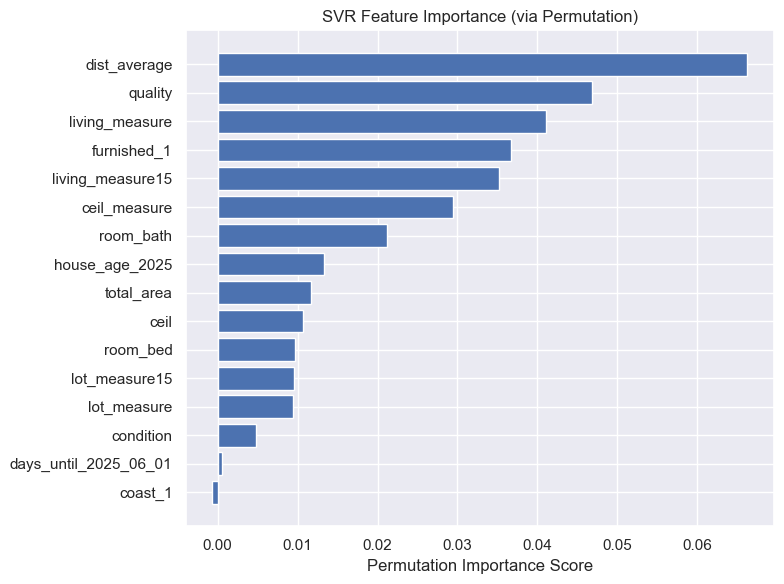

In [351]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    svr_model, X_test, y_test, n_repeats=30, random_state=42
)

import pandas as pd
import matplotlib.pyplot as plt

# Create DataFrame from importances
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": result.importances_mean
}).sort_values(by="Importance", ascending=True)

# Plot
plt.figure(figsize=(8, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"])
plt.xlabel("Permutation Importance Score")
plt.title("SVR Feature Importance (via Permutation)")
plt.tight_layout()
plt.show()